In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("netflix_titles.csv")
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [7]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [7]:
df[df.duplicated()]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description


In [ ]:
df["type"].unique()
df["rating"].unique()
df["country"].nunique()

748

In [ ]:
df["rating"].unique()


<StringArray>
[   'PG-13',    'TV-MA',       'PG',    'TV-14',    'TV-PG',     'TV-Y',
    'TV-Y7',        'R',     'TV-G',        'G',    'NC-17',   '74 min',
   '84 min',   '66 min',       'NR',        nan, 'TV-Y7-FV',       'UR']
Length: 18, dtype: str

In [3]:
df.dtypes

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

In [5]:
(df.isnull().sum()/len(df) * 100).round(2)

show_id          0.00
type             0.00
title            0.00
director        29.91
cast             9.37
country          9.44
date_added       0.11
release_year     0.00
rating           0.05
duration         0.03
listed_in        0.00
description      0.00
dtype: float64

In [11]:
# 1. Get all rows where cast is null
df["cast"] = df["cast"].fillna("Not specified")
df["country"] = df["country"].fillna("Not specified")
df["director"] = df["director"].fillna("unknown")


In [6]:
df.loc[df["director"].isnull(), ["title","type", "release_year", "country"]].head(10)

,title,type,release_year,country
1,Blood & Water,TV Show,2021,South Africa
3,Jailbirds New Orleans,TV Show,2021,NaN
4,Kota Factory,TV Show,2021,India
10,"Vendetta: Truth, Lies and The Mafia",TV Show,2021,NaN
14,Crime Stories: India Detectives,TV Show,2021,NaN
15,Dear White People,TV Show,2021,United States
17,Falsa identidad,TV Show,2020,Mexico
19,Jaguar,TV Show,2021,NaN
21,Resurrection: Ertugrul,TV Show,2018,Turkey
25,Love on the Spectrum,TV Show,2021,Australia


In [2]:
df_clean = df.copy()

In [4]:
df


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [3]:
df_clean.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [13]:
df_clean.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           4
duration         3
listed_in        0
description      0
dtype: int64

In [14]:
movie_serie_ratio = df_clean["type"].value_counts()
print(movie_serie_ratio)
print(movie_serie_ratio["Movie"])

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
6131


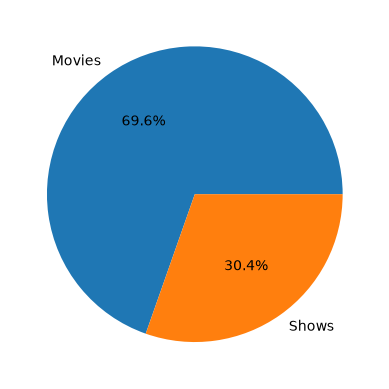

In [24]:
import matplotlib.pyplot as plt
a = movie_serie_ratio["Movie"]
b  = movie_serie_ratio["TV Show"]
plt.pie([a,b], labels=["Movies","Shows"], autopct="%1.1f%%")
plt.show()



In [27]:
df_clean.groupby(["release_year", "type"]).size().unstack(fill_value=0)

type,Movie,TV Show
release_year,,
1925,0,1
1942,2,0
1943,3,0
1944,3,0
1945,3,1
...,...,...
2017,767,265
2018,767,380
2019,633,397


In [30]:
df_clean[["date_added","title"]].head(10)

,date_added,title
0,2021-09-25,Dick Johnson Is Dead
1,2021-09-24,Blood & Water
2,2021-09-24,Ganglands
3,2021-09-24,Jailbirds New Orleans
4,2021-09-24,Kota Factory
5,2021-09-24,Midnight Mass
6,2021-09-24,My Little Pony: A New Generation
7,2021-09-24,Sankofa
8,2021-09-24,The Great British Baking Show
9,2021-09-24,The Starling


In [6]:
df_clean[["date_added","title","type","release_year"]].head(10).sort_values("release_year")

,date_added,title,type,release_year
7,"September 24, 2021",Sankofa,Movie,1993
0,"September 25, 2021",Dick Johnson Is Dead,Movie,2020
2,"September 24, 2021",Ganglands,TV Show,2021
1,"September 24, 2021",Blood & Water,TV Show,2021
3,"September 24, 2021",Jailbirds New Orleans,TV Show,2021
4,"September 24, 2021",Kota Factory,TV Show,2021
5,"September 24, 2021",Midnight Mass,TV Show,2021
6,"September 24, 2021",My Little Pony: A New Generation,Movie,2021
8,"September 24, 2021",The Great British Baking Show,TV Show,2021
9,"September 24, 2021",The Starling,Movie,2021


In [53]:
df_clean["date_added"] = pd.to_datetime(df["date_added"],format="mixed", errors="coerce")


In [54]:
df_clean["date_added"].isnull().sum()

np.int64(10)

In [27]:
df_clean.dtypes

show_id                    str
type                       str
title                      str
director                   str
cast                       str
country                    str
date_added      datetime64[us]
release_year             int64
rating                     str
duration                   str
listed_in                  str
description                str
date_addeed     datetime64[us]
year_added             float64
dtype: object

In [55]:
df_clean["year_added"] = df_clean["date_added"].dt.year
yearly_additions = (df_clean.groupby(["year_added", "type"]).size().unstack(fill_value=0))
yearly_additions

type,Movie,TV Show
year_added,,
2008.0,1,1
2009.0,2,0
2010.0,1,0
2011.0,13,0
2012.0,3,0
2013.0,6,5
2014.0,19,5
2015.0,56,26
2016.0,253,176


In [4]:
df_clean.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [41]:
df.loc[df["date_added"].notnull(), "date_added"].head(15)

0     September 25, 2021
1     September 24, 2021
2     September 24, 2021
3     September 24, 2021
4     September 24, 2021
5     September 24, 2021
6     September 24, 2021
7     September 24, 2021
8     September 24, 2021
9     September 24, 2021
10    September 24, 2021
11    September 23, 2021
12    September 23, 2021
13    September 22, 2021
14    September 22, 2021
Name: date_added, dtype: str

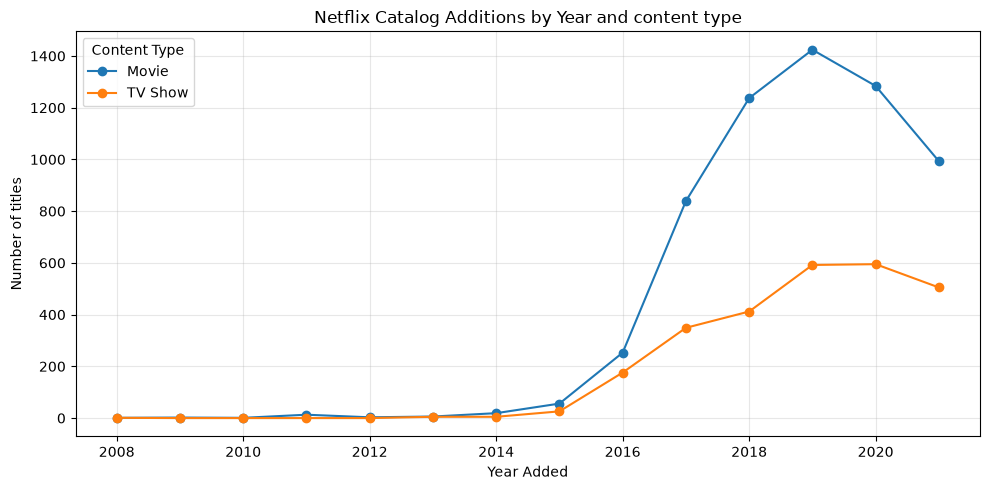

In [59]:
import matplotlib.pyplot as plt
yearly_additions.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Netflix Catalog Additions by Year and content type")
plt.xlabel("Year Added")
plt.ylabel("Number of titles")
plt.legend(title="Content Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
tv_show_share = (yearly_additions["TV Show"]/ yearly_additions.sum(axis=1) * 100)
tv_show_share.round(2)

year_added
2008.0    50.00
2009.0     0.00
2010.0     0.00
2011.0     0.00
2012.0     0.00
2013.0    45.45
2014.0    20.83
2015.0    31.71
2016.0    41.03
2017.0    29.38
2018.0    24.98
2019.0    29.37
2020.0    31.67
2021.0    33.71
dtype: float64

In [15]:
df_clean["rating"]

0       PG-13
1       TV-MA
2       TV-MA
3       TV-MA
4       TV-MA
        ...  
8802        R
8803    TV-Y7
8804        R
8805       PG
8806    TV-14
Name: rating, Length: 8807, dtype: str

In [16]:
df_clean["rating"].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

In [18]:
rating_counts = df_clean["rating"].value_counts()
rating_share = (rating_counts / len(df_clean)) * 100

rating_share.round(2)

rating
TV-MA       36.41
TV-14       24.53
TV-PG        9.80
R            9.07
PG-13        5.56
TV-Y7        3.79
TV-Y         3.49
PG           3.26
TV-G         2.50
NR           0.91
G            0.47
TV-Y7-FV     0.07
NC-17        0.03
UR           0.03
74 min       0.01
84 min       0.01
66 min       0.01
Name: count, dtype: float64

In [20]:
df_clean["listed_in"].value_counts().head(10)

listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            220
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, International Movies, Romantic Movies       180
Name: count, dtype: int64

In [22]:
df_clean["country"].value_counts().head(20)

country
United States                    2818
India                             972
Not specified                     831
United Kingdom                    419
Japan                             245
South Korea                       199
Canada                            181
Spain                             145
France                            124
Mexico                            110
Egypt                             106
Turkey                            105
Nigeria                            95
Australia                          87
Taiwan                             81
Indonesia                          79
Brazil                             77
United Kingdom, United States      75
Philippines                        75
United States, Canada              73
Name: count, dtype: int64